CIFAR classes:

| Label | Class | Description |
|---:|---|---|
| 0 | Airplane | Airplanes |
| 1 | Automobile | Cars |
| 2 | Bird | Birds |
| 3 | Cat | Cats |
| 4 | Deer | Deer |
| 5 | Dog | Dogs |
| 6 | Frog | Frogs |
| 7 | Horse | Horses |
| 8 | Ship | Ships |
| 9 | Truck | Trucks |


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


torch.Size([16, 3, 32, 32])


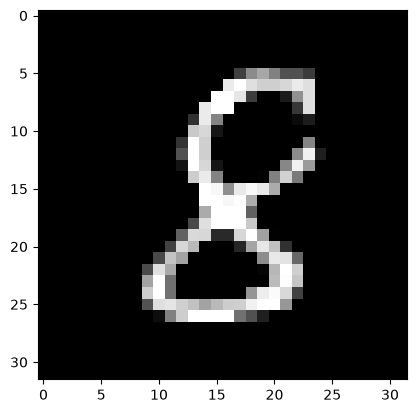

MNIST Minimal value: -1.0
MNIST Maximal value: 1.0


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9607843].


torch.Size([64, 3, 32, 32])
CIFAR Minimal value: -1.0
CIFAR Maximal value: 1.0
CIFAR train len: 782
CIFAR test len: 157


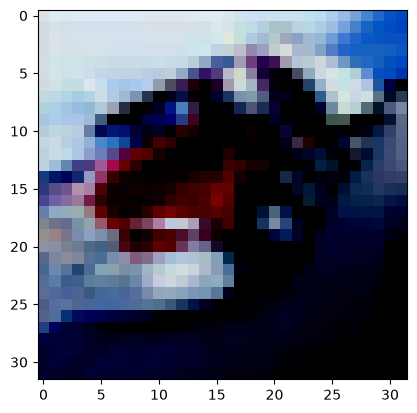

In [192]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torchvision
import torch
from dataset import CustomCIFARDataset

def cuda_memory():
    if torch.cuda.is_available():
        device = torch.cuda.current_device()
        props = torch.cuda.get_device_properties(device)

        total = props.total_memory
        allocated = torch.cuda.memory_allocated(device)
        reserved = torch.cuda.memory_reserved(device)

        print(f"GPU: {props.name}")
        print(f"Total GPU memory:     {total / 1024**3:.2f} GB")
        print(f"Allocated by PyTorch: {allocated / 1024**3:.2f} GB")
        print(f"Reserved by PyTorch:  {reserved / 1024**3:.2f} GB")
        print(f"Free within PyTorch:  {(reserved - allocated) / 1024**3:.2f} GB")
    else:
        print("CUDA is not available.")
    return 

def get_cifar_dataloaders(batch_size):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.5, 0.5, 0.5],
            std=[0.5, 0.5, 0.5]
        )
    ])
    seed = 52
    generator = torch.Generator()
    generator.manual_seed(seed)
    trainset = CustomCIFARDataset(
        root='./data', train=True, transform=transform
    )
    testset = CustomCIFARDataset(
        root='./data', train=False, transform=transform
    )
    train_dataloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, generator=generator)
    test_dataloader  = DataLoader(testset, batch_size=batch_size, shuffle=True, generator=generator)
    return train_dataloader, test_dataloader


def get_minst_dataloaders(batch_size):
    transform = transforms.Compose([
        transforms.Resize((32, 32)),                   # Optional: scale up slightly from 28x28
        transforms.Grayscale(num_output_channels=3), # Convert 1-channel MNIST to 3-channel RGB for KID
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]) # Scales [0, 1] to [-1, 1]
    ])
    seed = 42
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
    return train_dataloader

train_dataloader = get_minst_dataloaders(batch_size=16) 
img, _ = next(iter(train_dataloader))
print(img.shape)  # Output: torch.Size([3, 256, 256])

_=plt.imshow(img[0].permute(1,2,0))
_=plt.show()
print(f"MNIST Minimal value: {img.min()}")
print(f"MNIST Maximal value: {img.max()}")

train_dataloader, test_dataloader = get_cifar_dataloaders(batch_size=64) 
img, _ = next(iter(train_dataloader))
print(img.shape)  # Output: torch.Size([3, 256, 256])
_=plt.imshow(img[0].permute(1,2,0))
print(f"CIFAR Minimal value: {img.min()}")
print(f"CIFAR Maximal value: {img.max()}")
print(f"CIFAR train len: {len(train_dataloader)}")
print(f"CIFAR test len: {len(test_dataloader)}")

In [193]:
from unet2 import UNet

device = "cpu" if torch.cuda.is_available() else "cuda"

model = UNet(
    in_channels=3,
    out_channels=3,
    base_channels=32,
    time_dim=128
).to(device)

model.eval()

# Batch of 16 RGB images
x = torch.randn(16, 3, 32, 32, device=device)

# A different timestep for every image
t = torch.randint(0, 100, (16,), device=device)

with torch.no_grad():
    predicted_noise = model(x, t)

print("Input shape: ", x.shape)
print("Timestep shape:", t.shape)
print("Output shape:", predicted_noise.shape)

Input shape:  torch.Size([16, 3, 32, 32])
Timestep shape: torch.Size([16])
Output shape: torch.Size([16, 3, 32, 32])


# Diffusion train

torch.Size([100])


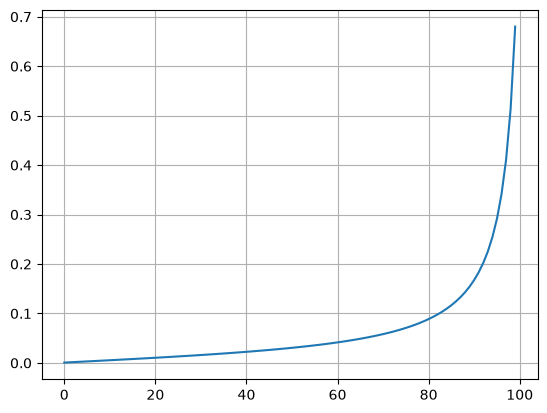

In [194]:

def diffusion_schedule(T, max_signal_rate=0.9999, min_signal_rate=0.02):
    # Generate T + 1 diffusion times
    t = torch.linspace(0, 1, T + 1)
    # Convert signal limits to angles
    start_angle = torch.arccos(torch.tensor(max_signal_rate))
    end_angle = torch.arccos(torch.tensor(min_signal_rate))
    # Calculate signal rates
    angles = start_angle + t * (end_angle - start_angle)
    signal_rates = torch.cos(angles)
    # Calculate cumulative signal coefficients
    alpha_bars = signal_rates ** 2

    # Normalize initial cumulative signal to 1
    alpha_bars = alpha_bars / alpha_bars[0]

    # Calculate T beta values
    betas = 1 - alpha_bars[1:] / alpha_bars[:-1]

    return torch.clamp(betas, min=0.0, max=0.999)

T = 100
betas = diffusion_schedule(T)

print(betas.shape)  # torch.Size([1000])

plt.plot(betas)
plt.grid()

In [195]:
import gc
import torch.nn.functional as F
gc.collect()
torch.cuda.empty_cache()
cuda_memory()

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU memory:     5.66 GB
Allocated by PyTorch: 0.09 GB
Reserved by PyTorch:  0.12 GB
Free within PyTorch:  0.03 GB


In [196]:
import torch

@torch.no_grad()
def reverse_sample(model, shape, T, betas, alpha_cumprod, sigmas=None, device="cuda"):
    model.eval()
    model = model.to(device)
    
    z = torch.randn(shape, device=device)

    for t in range(T, 1, -1):
        idx = t - 1  
        
        beta_t = betas[idx]
        alpha_t = alpha_cumprod[idx]
        
        t_batch = torch.full((shape[0],), idx, device=device, dtype=torch.long)
        g_t = model(z, t_batch)
        
        coef_z = 1.0 / torch.sqrt(1.0 - beta_t)
        coef_g = beta_t / (torch.sqrt(1.0 - alpha_t) * torch.sqrt(1.0 - beta_t))
        z_hat = coef_z * z - coef_g * g_t
        
        epsilon = torch.randn_like(z)
        
        #sigma_t = beta_t.sqrt() if sigmas is None else sigmas[idx]
        sigma_t = torch.sqrt((1-alpha_cumprod[idx-1])/(1-alpha_t)*beta_t) if sigmas is None else sigmas[idx]
        z = z_hat + sigma_t * epsilon

    beta_1 = betas[0]
    alpha_1 = alpha_cumprod[0]
    t_1 = torch.zeros((shape[0],), device=device, dtype=torch.long)
    g_1 = model(z, t_1)
    
    coef_z1 = 1.0 / torch.sqrt(1.0 - beta_1)
    coef_g1 = beta_1 / (torch.sqrt(1.0 - alpha_1) * torch.sqrt(1.0 - beta_1))
    
    x = coef_z1 * z - coef_g1 * g_1
    return x


# Hyperparameters

DEVICE=cuda


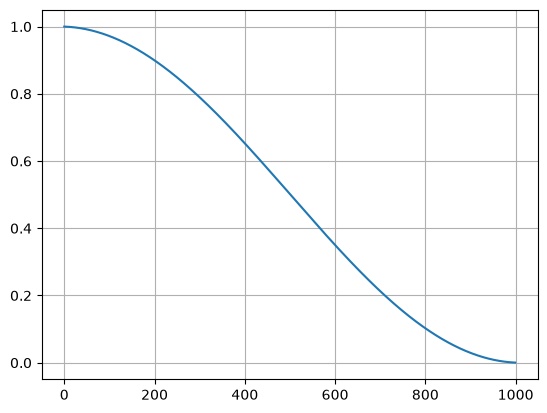

In [ ]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm
from torch.optim.lr_scheduler import CosineAnnealingLR

batch_size = 64
# dataloader = get_minst_dataloaders(batch_size=batch_size) 
train_dataloader, test_dataloader = get_cifar_dataloaders(batch_size=batch_size) 


T = 1000
epochs = 1000
model = UNet(in_channels=3, out_channels=3)
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,  # Learning rate
    weight_decay=1e-4,  # L2 penalty (optional)
)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"DEVICE={device}")
model = model.to(device)

# Generate the beta schedule
betas = diffusion_schedule(T).to(device)

# Precompute cumulative signal coefficients
alpha_cumprod = torch.cumprod(1.0 - betas, dim=0).to(device)

plt.plot(alpha_cumprod.cpu())
plt.grid()

batch_losses = []
kid_steps    = []
kid_means    = []

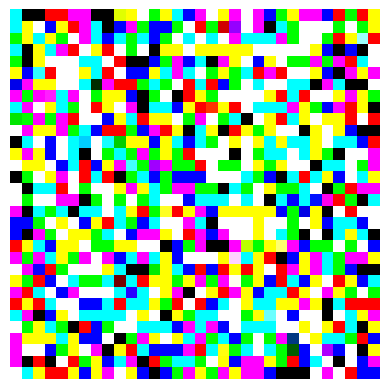

In [198]:
import torchvision
from torchmetrics.image.kid import KernelInceptionDistance

def vizualize_batch(model, batch_size, T, betas, alpha_cumprod, device):
    batch_results = reverse_sample(model=model, 
                        shape=(batch_size, 3, 32, 32), 
                        T=T, 
                        betas=betas, 
                        alpha_cumprod=alpha_cumprod, 
                        sigmas=None, 
                        device=device)
    normalized_results = (batch_results * 0.5 + 0.5)
    grid_img = torchvision.utils.make_grid(normalized_results.cpu(), nrow=4, padding=10)
    plt.axis("off")
    _=plt.imshow(grid_img.permute(1, 2, 0).clamp(0,1).numpy())
    plt.show()

def evaluate(dataloader,
             model, 
             T, 
             betas, 
             alpha_cumprod, 
             device):
    
    # Suppose your subset_size is 100, but your batch size is 32
    kid = KernelInceptionDistance(subset_size=100).to(device)

    # Accumulate across multiple batches until you hit at least 100 images
    i = 0
    for real_imgs, _ in dataloader:
        # real_imgs.shape is e.g. [32, 3, 256, 256]
        batch_size = len(real_imgs)
        fake_imgs = reverse_sample(model=model, 
                                   shape=real_imgs.shape, 
                                   T=T, 
                                   betas=betas, 
                                   alpha_cumprod=alpha_cumprod, 
                                   sigmas=None, 
                                   device=device)

        # Preprocess fake images to match requirements [0, 255] uint8
        fake_imgs = ((fake_imgs * 0.5 + 0.5).clamp(0,1) * 255.0).byte()
        real_imgs = ((real_imgs * 0.5 + 0.5).clamp(0,1) * 255.0).byte()
        
        # Feed them into the KID metric (it keeps an internal buffer)
        kid.update(real_imgs.to(device), real=True)
        kid.update(fake_imgs.to(device), real=False)
        i += 1
        # Optional: break once you've collected enough batches (e.g., 4 batches * 32 = 128 images)
        if i*batch_size >= 100:
            break

    kid_mean, kid_std = kid.compute()
    return kid_mean.cpu().item(), kid_std.cpu().item()

vizualize_batch(model, batch_size, T, betas, alpha_cumprod, "cuda")
#evaluate(test_dataloader, model, T, betas, alpha_cumprod, device)


Epoch 1/1000:   6%|▌         | 2995/50000 [00:41<10:27, 74.93it/s]

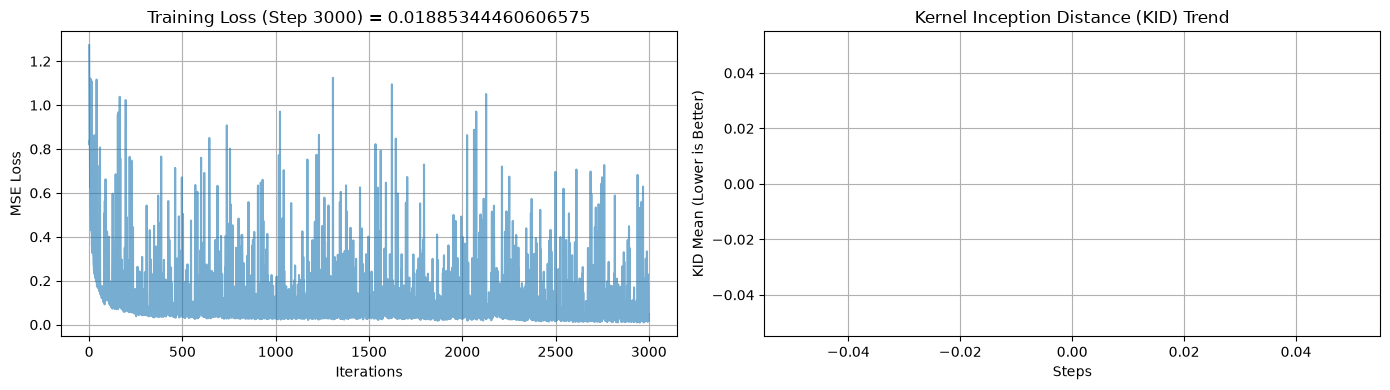

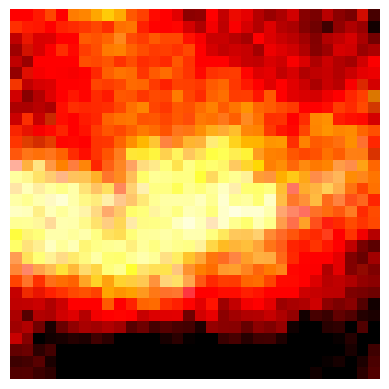

Epoch 1/1000:   6%|▌         | 3085/50000 [00:46<13:19, 58.65it/s]  

In [ ]:
def diagnostics(step, batch_losses, kid_steps, kid_means, model, dataloader, T, betas, alpha_cumprod, device, evaluate=True):
    if evaluate:
        print(f"\n--- Running KID Evaluation at Step {step} ---")
        kid_mean, kid_std = evaluate(dataloader, model, T, betas, alpha_cumprod, device)
        print(f"KID Score: {kid_mean:.5f} ± {kid_std:.5f}\n")
        # Store history for plotting
        kid_steps.append(step)
        kid_means.append(kid_mean)

    # Plot Loss and KID side-by-side or stacked
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Plot Training Loss
    axes[0].plot(batch_losses, color='tab:blue', alpha=0.6)
    axes[0].set_title(f"Training Loss (Step {step}) = {batch_losses[-1]}")
    axes[0].set_xlabel("Iterations")
    axes[0].set_ylabel("MSE Loss")
    axes[0].grid(True)
    
    # Plot KID Score Trend
    axes[1].plot(kid_steps, kid_means, marker='o', color='tab:orange', linestyle='-')
    axes[1].set_title("Kernel Inception Distance (KID) Trend")
    axes[1].set_xlabel("Steps")
    axes[1].set_ylabel("KID Mean (Lower is Better)")
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

    vizualize_batch(model, batch_size, T, betas, alpha_cumprod, "cuda")



for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for i, (img_batch, _) in enumerate(tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{epochs}")):
        global_step = epoch * len(train_dataloader) + i

        optimizer.zero_grad()
        img_batch = img_batch.to(device) # img_batch: 16, 3, 256, 256

        current_batch_size = img_batch.shape[0]
        t = torch.randint(0, T, (current_batch_size,), device=device)
        epsilon = torch.randn_like(img_batch) # 16, 3, 256, 256

        alpha_bar_t = alpha_cumprod[t]
        alpha_bar_t = alpha_bar_t.view(-1, 1, 1, 1)

        noisy_images = (
            torch.sqrt(alpha_bar_t) * img_batch
            + torch.sqrt(1.0 - alpha_bar_t) * epsilon
        )

        predicted_noise = model(noisy_images, t)

        batch_loss = F.mse_loss(predicted_noise, epsilon)
        batch_loss.backward()

        epoch_loss += batch_loss.item()
        optimizer.step()
        scheduler.step()
        batch_losses.append(batch_loss.item())

        if global_step != 0 and global_step % 3000 == 0:
            diagnostics(
                step=global_step, 
                batch_losses=batch_losses, 
                kid_steps=kid_steps, 
                kid_means=kid_means, 
                model=model, 
                dataloader=test_dataloader, 
                T=T, 
                betas=betas, 
                alpha_cumprod=alpha_cumprod, 
                device=device,
                evaluate=False
            )
    epoch_loss /= len(train_dataloader)
    tqdm.write(f"* EPOCH LOSS={epoch_loss:.6f}")
    torch.save(model.state_dict(), f"models/unet_weights_epoch_{epoch+1}.pth")

    
# Save model weights

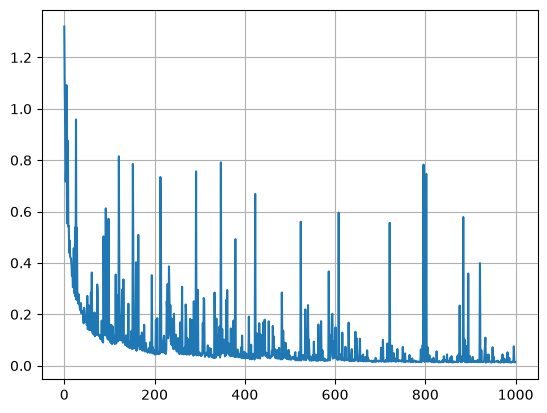

In [187]:
plt.plot(batch_losses)
plt.grid()

# Sampling and vizualization

In [8]:
import torch
from pathlib import Path
path = "models/unet"

device = "cuda" if torch.cuda.is_available() else "cpu"
results = {}
for i, ps in enumerate(list(Path("models").glob("unet*"))):
    print(i)
    model_epoch = int(str(ps).split("_")[-1].split(".")[0])
    model.load_state_dict(torch.load(ps, map_location=device))
    kid_mean, _ = evaluate(test_dataloader, model, T, betas, alpha_cumprod, device)
    results[model_epoch] = kid_mean

sorted_values = [(k,v) for k, v in sorted(results.items())]
xs = [x[0] for x in sorted_values]
ys = [x[1] for x in sorted_values]
plt.plot(xs,ys, marker="o")
plt.grid()
_=plt.xticks(range(len(sorted_values)+1))


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134


KeyboardInterrupt: 

In [ ]:
index = min(results, key=lambda v:results[v])

82

KID measure accross epochs

In [189]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
weights_path = "models/unet_weights_epoch_999.pth"
model.load_state_dict(torch.load(weights_path, map_location=device))

<All keys matched successfully>

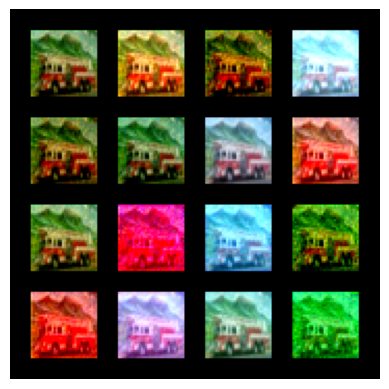

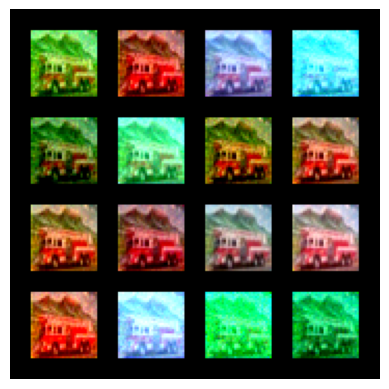

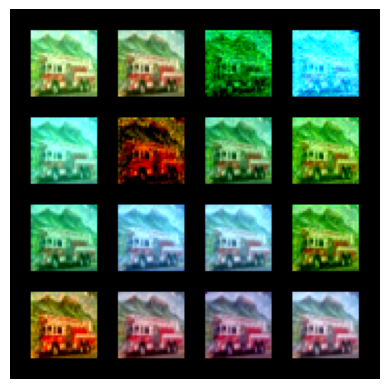

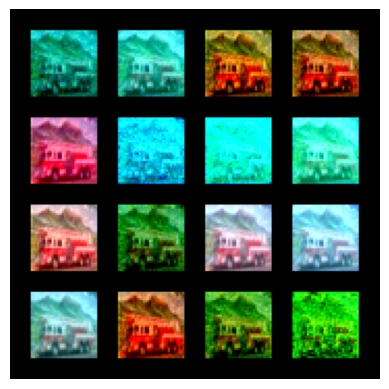

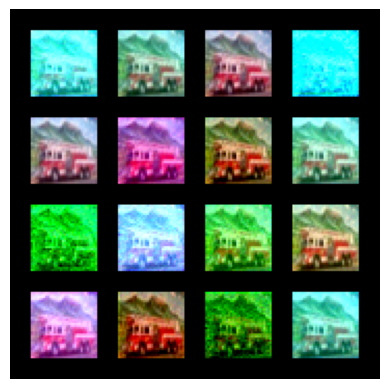

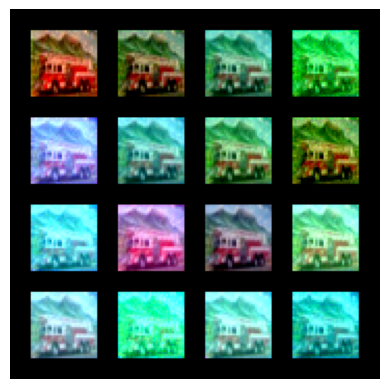

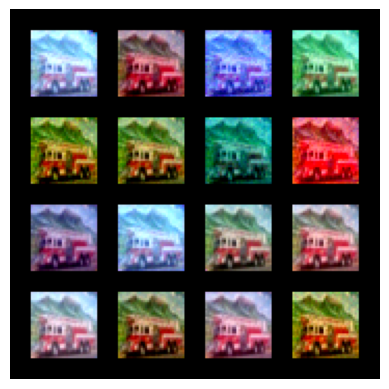

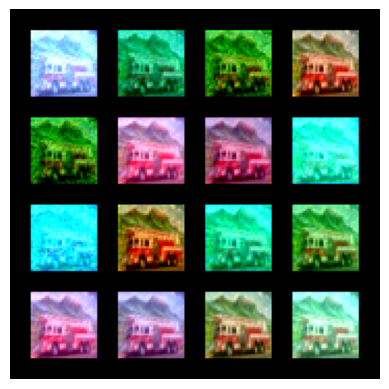

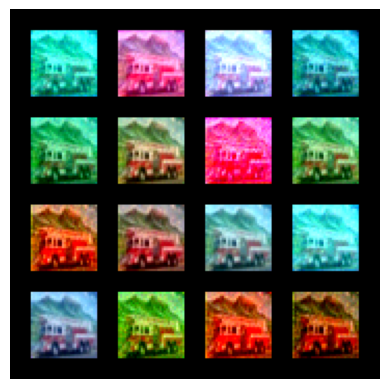

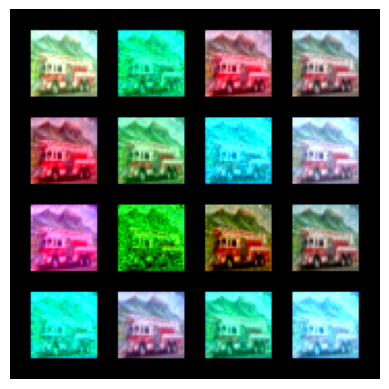

In [190]:

for i in range(10):
    batch_size = 16
    betas = diffusion_schedule(T).to(device)
    alpha_cumprod = torch.cumprod(1.0 - betas, dim=0)
    vizualize_batch(model, batch_size, T, betas, alpha_cumprod, device)
